## Now i use Elbow method to find best value of K to perform K-mean Clustering :-

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")


In [2]:
x , y_true = make_blobs(n_samples = 500 , centers = 3 , cluster_std = 0.60 , random_state = 42)
                        

In [3]:
df = pd.DataFrame(x , columns = ["Feature1","Feature2"])

In [4]:
df

,Feature1,Feature2
0,-6.190063,-7.302015
1,3.021747,1.940593
2,5.953761,1.488191
3,-2.744463,8.136177
4,5.360607,1.728324
...,...,...
495,-6.040014,-6.325329
496,-2.555459,9.218977
497,4.438408,2.974583
498,-7.193261,-6.250704


In [5]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(df)

In [6]:
wcss = []
k_range = range(1,11)
for k in k_range:
    kmean = KMeans(n_clusters = k,
                   random_state = 42)
    kmean.fit(x_scaled)
    wcss.append(kmean.inertia_)
    

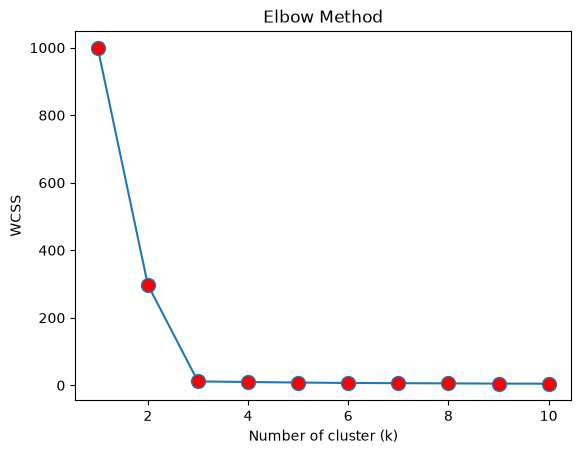

In [7]:
plt.plot(k_range , wcss , marker = 'o' , markersize = 10 , markerfacecolor = 'red')
plt.title("Elbow Method")
plt.xlabel("Number of cluster (k)")
plt.ylabel("WCSS")
plt.show()

In [8]:
kmeans_final = KMeans(n_clusters = 3 , random_state = 42)
cluster_label = kmeans_final.fit_predict(x_scaled)

In [9]:
df["Cluster"] = cluster_label

In [10]:
df

,Feature1,Feature2,Cluster
0,-6.190063,-7.302015,1
1,3.021747,1.940593,0
2,5.953761,1.488191,0
3,-2.744463,8.136177,2
4,5.360607,1.728324,0
...,...,...,...
495,-6.040014,-6.325329,1
496,-2.555459,9.218977,2
497,4.438408,2.974583,0
498,-7.193261,-6.250704,1


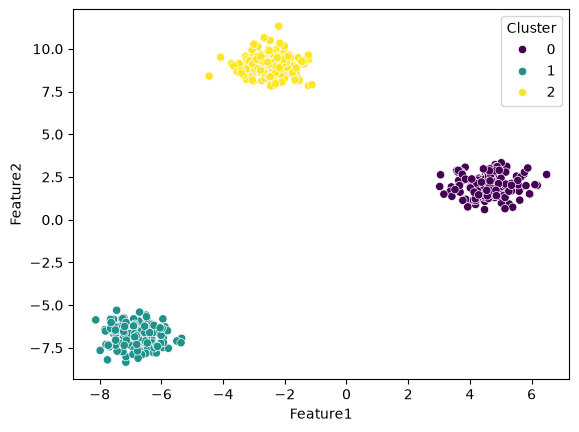

In [12]:
sns.scatterplot(x = df["Feature1"] , y = df["Feature2"] , hue = df["Cluster"] , palette = "viridis")
plt.show()